In [1]:
import seaborn

from astropy import units
from astropy.time import Time

from selflensing.generators import RVGenerator, LightcurveGenerator
from selflensing.fitting import self_lensing_system_from_fit

from realistic import load_realistic_timeseries
from utils import DEFAULTS, default_rv_times

In [2]:
rts = load_realistic_timeseries()

In [3]:
rts = rts[(rts['Porb'] > 60) & (rts['Porb'] < 150)]
len(rts)

70400

In [4]:
idx = 500
ts = rts.iloc[idx]

In [5]:
ts

a                                                           0.644444
e                                                                0.2
periapsis_phase                                             0.698132
Macc                                                        2.311111
Porb                                                      103.846001
Mcomp                                                            1.0
Rcomp                                                            1.0
b                                                                0.0
rv                 [55649.71757814352, 85479.11394679251, 110673....
rv_times           [2460676.5, 2460680.1868686867, 2460683.873737...
lc                 [0.9996236175490195, 0.9992925327558692, 0.998...
lc_times           [2460310.5, 2460314.196969697, 2460317.8939393...
peak_time                                                  2460462.5
rv_err                                                     10.004499
RV accuracy                       

<Axes: xlabel='rv_times', ylabel='rv'>

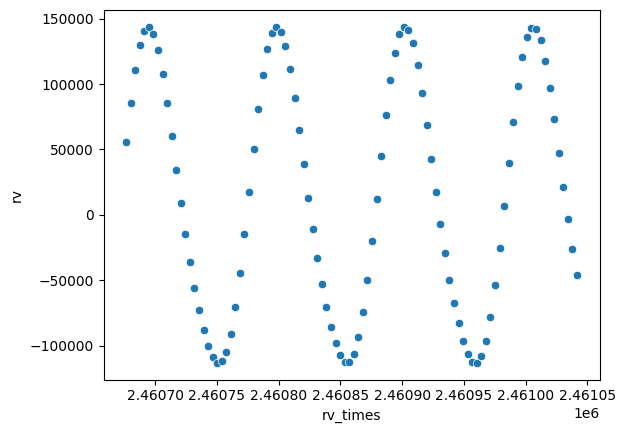

In [6]:
seaborn.scatterplot(ts.to_dict(), x='rv_times', y='rv')

<Axes: xlabel='lc_times', ylabel='lc'>

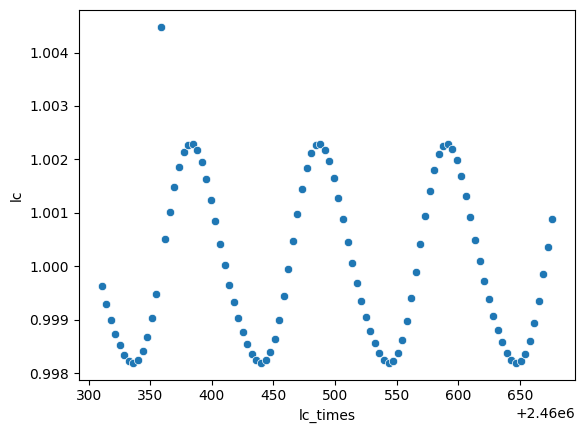

In [7]:
seaborn.scatterplot(ts.to_dict(), x='lc_times', y='lc')

In [8]:
from selflensing.lombscargle import get_periods

get_periods(ts['lc'], ts['lc_times'])

array([122.        , 114.375     , 107.64705882, 101.66666667,
        96.31578947,  91.5       ,   3.85263158,   3.84453782,
         3.83647799,   3.82845188,   3.82045929,   3.8125    ,
         3.58823529,   3.58121331,   3.57421875,   3.56725146,
         3.56031128,   3.55339806])

In [9]:
sls, sampler = self_lensing_system_from_fit(
    rv_times=Time(ts['rv_times'], format='jd'),
    observed_rv=ts['rv'] * units.m / units.s,
    observed_rv_err=ts['rv_err'] * units.m / units.s,
    lc_times=Time(ts['lc_times'], format='jd'),
    observed_lc=ts['lc'] * units.dimensionless_unscaled,
    observed_lc_err=1 * units.dimensionless_unscaled,
    peak_time=Time(ts['peak_time'], format='jd'),
    Mcomp=DEFAULTS['Mcomp'],
    Rcomp=DEFAULTS['Rcomp'],
    Teff=DEFAULTS['Teff'],
    nsteps=2000,
    nwalkers=50,
    burn=10,
)

  0%|          | 0/2000 [00:00<?, ?it/s]/Users/adam/.local/share/virtualenvs/src-VJqicAka/lib/python3.11/site-packages/emcee/moves/red_blue.py:99: RuntimeWarning: invalid value encountered in scalar subtract
  lnpdiff = f + nlp - state.log_prob[j]
100%|██████████| 2000/2000 [00:41<00:00, 47.75it/s]


In [10]:
import numpy
numpy.median(sampler.get_chain(flat=True, discard=100), axis=0)

array([0.64475587, 2.31127833, 0.20015517, 0.87004557])

In [11]:
# sls.a = 1 * units.AU
rvg = RVGenerator(sls, Time(ts['rv_times'], format='jd'), Time(ts['peak_time'], format='jd'))

In [12]:
sls.a, sls.Macc, sls.e, sls.periapsis_phase, sls.porb

(<Quantity 0.64443853 AU>,
 <Quantity 2.31102471 solMass>,
 <Quantity 0.20002202>,
 <Quantity 0.69818862 rad>,
 <Quantity 103.8459261 d>)

<Axes: xlabel='rv_times', ylabel='rv'>

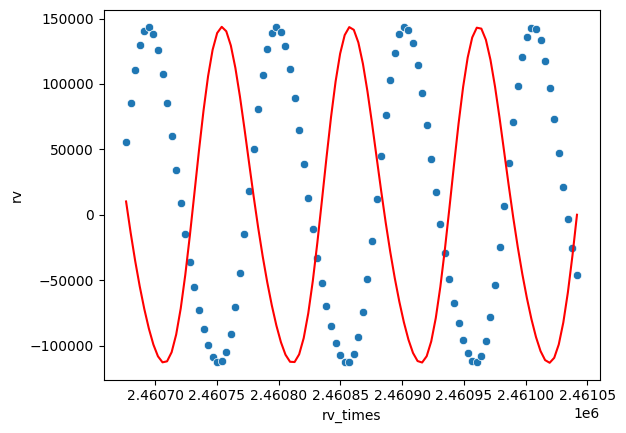

In [13]:
seaborn.scatterplot(ts.to_dict(), x='rv_times', y='rv')
seaborn.lineplot({'times': ts['rv_times'], 'rv': rvg.rv}, x='times', y='rv', color='red')

<Axes: xlabel='lc_times', ylabel='lc'>

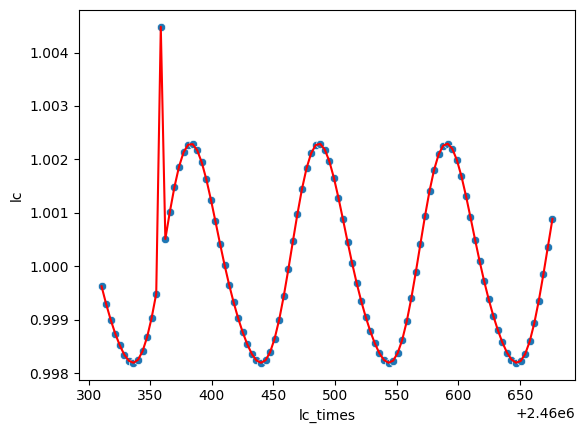

In [14]:
lcg = LightcurveGenerator(lensing_system=sls, times=Time(ts['lc_times'], format='jd'), peak_time=Time(ts['peak_time'], format='jd'))


seaborn.scatterplot(ts.to_dict(), x='lc_times', y='lc')
seaborn.lineplot({'times': ts['lc_times'], 'lc': lcg.flux_array}, x='times', y='lc', color='red')

Text(0.5, 0, 'step number')

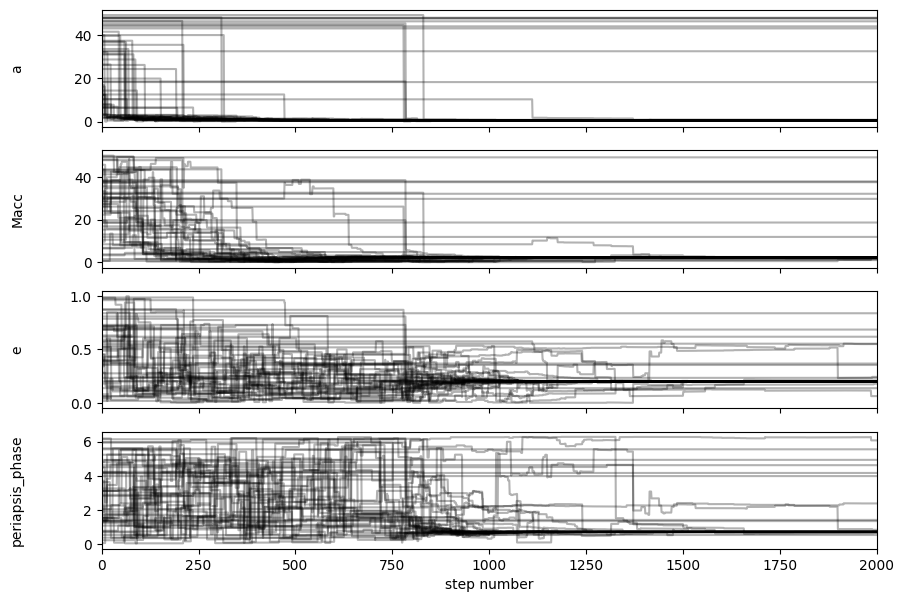

In [15]:
from matplotlib import pyplot as plt
labels = ["a", "Macc", 'e', 'periapsis_phase']
fig, axes = plt.subplots(len(labels), figsize=(10, 7), sharex=True)
samples = sampler.get_chain()#discard=100)
flat_samples = sampler.get_chain(flat=True)
for i in range(len(labels)):
    ax = axes[i]
    ax.plot(samples[:, :, i], "k", alpha=0.3)
    ax.set_xlim(0, len(samples))
    ax.set_ylabel(labels[i])
    ax.yaxis.set_label_coords(-0.1, 0.5)

axes[-1].set_xlabel("step number")

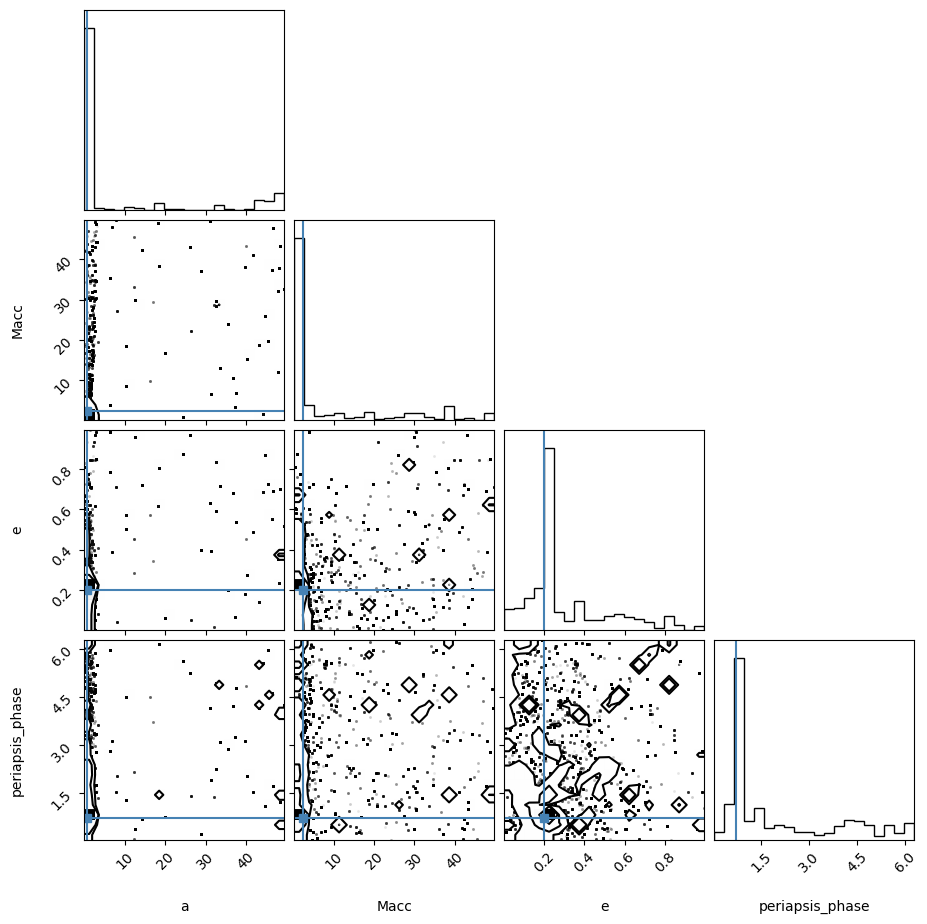

In [16]:
import corner

fig = corner.corner(
    flat_samples, labels=labels, truths=[ts['a'], ts['Macc'], ts['e'], ts['periapsis_phase']]
)